In [1]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage

print("🎉 Subsea Terrain Parameter Extraction Engine Active.")

def compute_slope_and_aspect(elevation_matrix, cell_size=2.0):
    """
    Computes Slope Gradient and Aspect from an elevation grid
    using Horn's partial derivative algorithms.
    """
    # Calculate partial derivatives using Sobel filters
    dz_dx = ndimage.sobel(elevation_matrix, axis=1) / (8.0 * cell_size)
    dz_dy = ndimage.sobel(elevation_matrix, axis=0) / (8.0 * cell_size)
    
    # Rise over run magnitude for Slope Gradient (degrees)
    slope = np.arctan(np.sqrt(dz_dx**2 + dz_dy**2)) * (180.0 / np.pi)
    
    # Directional orientation for Aspect (degrees from North)
    aspect = np.arctan2(-dz_dy, dz_dx) * (180.0 / np.pi)
    aspect = np.where(aspect < 0, aspect + 360, aspect)
    
    return slope, aspect

def compute_roughness(elevation_matrix, window_size=3):
    """
    Computes Seabed Roughness Index (SRI) as the standard deviation
    of elevations within a localized moving spatial window.
    """
    return ndimage.generic_filter(elevation_matrix, np.std, size=window_size)

# --- REUSABLE PIPELINE SIMULATION ---
# Creating a dummy 100x100 bathymetric channel feature to verify filters
np.random.seed(42)
y, x = np.mgrid[-5:5:100j, -5:5:100j]
simulated_bathymetry = -(x**2 + y**2) + np.random.normal(0, 0.05, x.shape) # Represents a seabed depression/trench

# Execute algorithms
slope_grid, aspect_grid = compute_slope_and_aspect(simulated_bathymetry, cell_size=2.0)
roughness_grid = compute_roughness(simulated_bathymetry, window_size=3)

print("\nSuccessfully processed morphodynamic drivers:")
print(f"-> Max Slope Gradient: {np.max(slope_grid):.2f}°")
print(f"-> Mean Seabed Roughness (SRI): {np.mean(roughness_grid):.4f} meters")



🎉 Subsea Terrain Parameter Extraction Engine Active.

Successfully processed morphodynamic drivers:
-> Max Slope Gradient: 35.43°
-> Mean Seabed Roughness (SRI): 0.6278 meters


🎉 Verification maps saved to: /Users/macbookpro2020/niger-delta-phd/07_figures


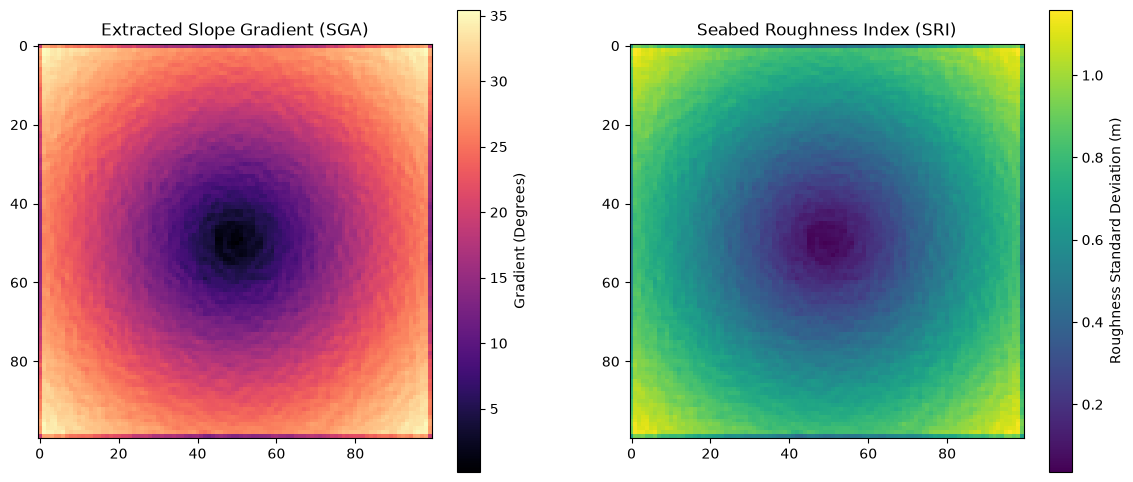

In [2]:
# Visualize the extracted terrain characteristics
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Slope Gradient
im1 = axes[0].imshow(slope_grid, cmap='magma')
axes[0].set_title('Extracted Slope Gradient (SGA)')
fig.colorbar(im1, ax=axes[0], label='Gradient (Degrees)')

# Plot 2: Seabed Roughness Index
im2 = axes[1].imshow(roughness_grid, cmap='viridis')
axes[1].set_title('Seabed Roughness Index (SRI)')
fig.colorbar(im2, ax=axes[1], label='Roughness Standard Deviation (m)')

# Save visual outputs natively to your 07_figures tier
home_path = os.path.expanduser("~")
output_fig_dir = os.path.join(home_path, "niger-delta-phd", "07_figures")
os.makedirs(output_fig_dir, exist_ok=True)

plt.savefig(os.path.join(output_fig_dir, "03_terrain_extraction_verification.png"), dpi=300, bbox_inches='tight')
print(f"🎉 Verification maps saved to: {output_fig_dir}")
plt.show()
